# Kernels and Pure-Phase Reconstructions

> Georgios Varnavides | Oct 8 2026
>
> Sample: a 2-unit-cell SrTiO$_3$ film, and a 78 A SrTiO$_3$ crystal
> Sampling conditions: 0.2 A step-size, and 0.4 A for upsampling
> Imaging conditions: 300 kV, 25 mrad, 100 A underfocus at the mid-plane
> Dose conditions: 1e5 and 1e4 e/A2

Direct ptychography reconstructs a specimen from a 4D-STEM dataset in a single pass over the
bright-field disk, without iterating. This first notebook introduces the model behind it, the six
deconvolution kernels `DirectPtychography` offers, and two settings every kernel shares: the
bright-field mask and upsampling. The datasets are simulated with a known phase, in
`simulation_notebooks/twisted-srtio3-membranes.ipynb`.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import numpy as np

import quantem as em

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The forward model

A 4D-STEM dataset records a diffraction pattern at every probe position. The intensity at one
bright-field pixel $\mathbf{k}$, as a function of probe position, is a virtual bright-field
image. For a weak phase object $\phi(\mathbf{r})$, its Fourier transform over the scan at a
spatial frequency $\mathbf{q} \neq 0$ is

$$G(\mathbf{q}, \mathbf{k}) = \Gamma(\mathbf{q}, \mathbf{k})\, i\tilde\phi(\mathbf{q}), \qquad
\Gamma(\mathbf{q}, \mathbf{k}) = \psi(\mathbf{k} - \mathbf{q})\,\psi^*(\mathbf{k})
- \psi^*(\mathbf{k} + \mathbf{q})\,\psi(\mathbf{k}),$$

where $\tilde\phi$ is the spectrum of the phase and $\psi(\mathbf{k}) = A(\mathbf{k})\,
e^{-i\chi(\mathbf{k})}$ is the probe, an aperture $A$ with the aberration function $\chi$.
$\Gamma$ is non-zero where the aperture overlaps its copies shifted by $\pm\mathbf{q}$. Every
bright-field pixel measures the same spectrum through its own overlap function, and a direct
reconstruction combines them at every $\mathbf{q}$. The kernels differ in how:

| kernel | aliases | how it combines the bright-field pixels |
|---|---|---|
| `"ssb"` | `"single-sideband"`, `"acbf"` | the double-overlap regions, each normalized to unit weight |
| `"obf"` | `"optimum-bright-field"` | weighted by $\Gamma^*$ and scaled to white noise, $\sum_\mathbf{k} \Gamma^* G \,/ \sqrt{\sum_\mathbf{k} \lvert\Gamma\rvert^2}$ |
| `"wiener"` | | the same least-squares problem, shrunk by a signal spectrum estimated from the data, an estimate of the object itself |
| `"wdd"` | `"wigner-distribution-deconvolution"` | Wigner distribution deconvolution of the intensity, with no weak-object approximation |
| `"prlx"` | `"parallax"`, `"tcbf"` | each image shifted back by the gradient of $\chi$, then summed |
| `"icom"` | `"center-of-mass"` | the integrated center of mass, which needs no aberrations |

In [3]:
def add_poisson_noise(dataset, electrons_per_area, seed=2025):
    rng = np.random.default_rng(seed)
    electrons_per_probe = electrons_per_area * np.prod(dataset.sampling[-4:-2])
    dataset_noisy = dataset.copy()
    dataset_noisy.array = rng.poisson(dataset.array * electrons_per_probe).astype(np.float32)
    return dataset_noisy


def correlation(a, b):
    a, b = (np.asarray(x.cpu() if hasattr(x, "cpu") else x, dtype=np.float64) for x in (a, b))
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def scale(image, truth):
    """Least-squares scale of the image on the truth: one when the values are the true phase."""
    image, truth = image - image.mean(), truth - truth.mean()
    return float((image * truth).sum() / (truth * truth).sum())

In [4]:
energy = 300e3
semiangle_cutoff = 25
C10 = -100

kernels = ["ssb", "obf", "wiener", "wdd", "prlx", "icom"]
kwargs = dict(
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=0,
    aberration_coefs={"C10": C10},
    verbose=False,
    # device='gpu',
)

## A first reconstruction

`DirectPtychography.from_dataset4d` keeps the bright-field pixels, fits and removes the origin
of the diffraction patterns, and stores the aberrations and the rotation between the detector
and the scan. `reconstruct` then runs one kernel, and `obj` holds the result. We start with a
2-unit-cell SrTiO$_3$ film, 7.8 A thick, whose strongest columns shift the phase by up to
1.6 rad, at 1e5 electrons per square Angstrom:

correlation with the true phase: 0.894


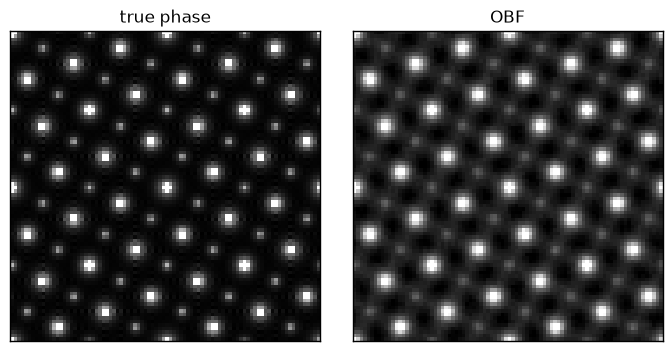

In [5]:
film = em.core.io.load("../../data/STO-film_300kV_25mrad.zip")
film_truth = em.core.io.load("../../data/STO-film_truth.zip").array[0]

direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(film, 1e5), **kwargs
)
direct_ptycho.reconstruct(deconvolution_kernel="obf")
print(f"correlation with the true phase: {correlation(direct_ptycho.obj, film_truth):.3f}")

em.visualization.show_2d(
    [film_truth, direct_ptycho.obj],
    title=["true phase", "OBF"],
    axsize=(3.5, 3.5),
);

## Six kernels

`_reconstruct_all_permutations` runs every kernel with the same settings:

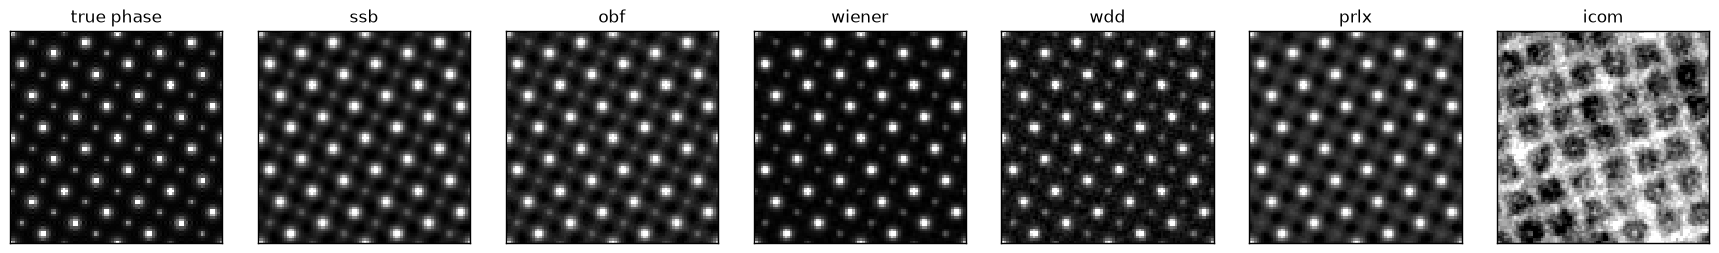

In [6]:
recons = direct_ptycho._reconstruct_all_permutations()

em.visualization.show_2d(
    [film_truth] + recons,
    title=["true phase"] + kernels,
    axsize=(2.5, 2.5),
);

In [7]:
def kernel_table(recons, truth):
    print(f"{'kernel':>8} {'correlation':>12} {'scale':>8}")
    for kernel, recon in zip(kernels, recons):
        print(f"{kernel:>8} {correlation(recon, truth):12.3f} {scale(recon, truth):8.3f}")


kernel_table(recons, film_truth)

  kernel  correlation    scale
     ssb        0.890    1.001
     obf        0.894    0.967
  wiener        0.932    0.726
     wdd        0.946    0.739
    prlx        0.867    0.947
    icom       -0.186   -0.024


The correlation measures how well each image follows the true phase. The scale is the
least-squares factor between the image and the truth, which is one if the values are the phase
in radians.

- SSB, OBF and parallax come close to the true scale on this film, but their transfer varies
  with spatial frequency and with the aberrations, so this is not a calibration.
- The Wiener estimate and WDD correlate best with the truth. Wiener treats everything the
  weak-object model leaves unexplained as noise, which on this film includes the multiple
  scattering and propagation inside it, and shrinks the frequencies where that is large. Its
  scale is therefore below one even on noise-free data.
- WDD's deconvolution is regularized by a fixed `ridge`, so its values are not calibrated either.
- iCoM's image is a low-pass of the phase by the probe intensity, which the 100 A defocus
  spreads over several Angstrom, so it correlates poorly at this defocus.

At ten times lower dose the Wiener estimate holds up best, and WDD, which divides by a weak
ambiguity function wherever the ridge allows, loses the most:

In [8]:
direct_ptycho_low_dose = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(film, 1e4), **kwargs
)
kernel_table(direct_ptycho_low_dose._reconstruct_all_permutations(), film_truth)

  kernel  correlation    scale
     ssb        0.880    1.004
     obf        0.877    0.968
  wiener        0.911    0.708
     wdd        0.854    0.734
    prlx        0.851    0.948
    icom       -0.099   -0.027


## A thick crystal

Twenty unit cells, 78 A, in the same orientation. The weak-object kernels model the data as
linear in the phase, which fails at this thickness. WDD deconvolves the intensity itself and
recovers a single multiplicative transmission function $T(\mathbf{r})$, so its phase is
$\arg T$, wrapped to $(-\pi, \pi]$, and its log-amplitude $\ln |T|$.

     ssb: correlation with the projected potential 0.581
     obf: correlation with the projected potential 0.539
  wiener: correlation with the projected potential 0.464
     wdd: correlation with the projected potential 0.797


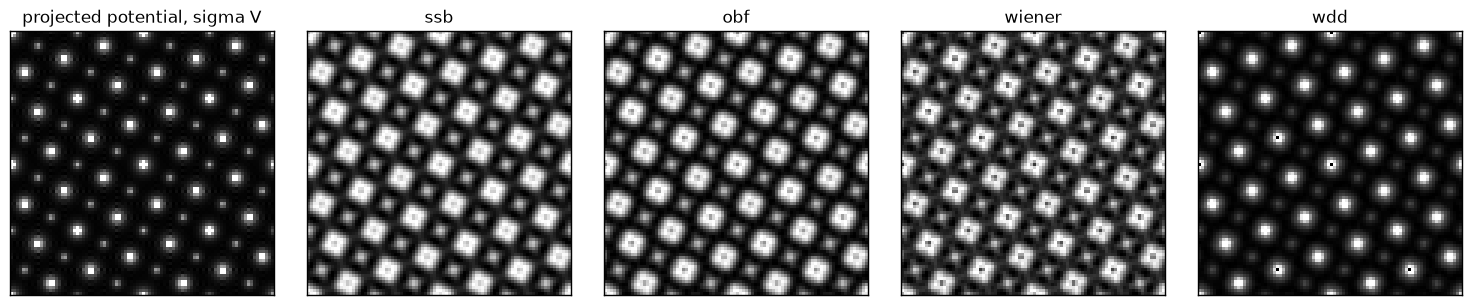

In [9]:
thick = em.core.io.load("../../data/STO-thick_300kV_25mrad.zip")
thick_truth = em.core.io.load("../../data/STO-thick_truth.zip").array[0]

direct_ptycho_thick = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(thick, 1e5), **kwargs
)

images = {}
for kernel in ("ssb", "obf", "wiener", "wdd"):
    direct_ptycho_thick.reconstruct(deconvolution_kernel=kernel)
    images[kernel] = direct_ptycho_thick.corrected_bf.cpu().numpy()
    print(f"{kernel:>8}: correlation with the projected potential {correlation(images[kernel], thick_truth):.3f}")

em.visualization.show_2d(
    [thick_truth] + list(images.values()),
    title=["projected potential, sigma V"] + list(images),
    axsize=(3, 3),
);

WDD follows the projected potential far better than the weak-object kernels. Its phase wraps
where a column shifts the phase by more than $\pi$, which shows as a dark centre on the
strongest columns.

## The bright-field mask

Every kernel uses only the bright-field pixels. By default the mask is the model aperture:
the detector pixels where the probe model is non-zero and the mean pattern records signal.
`intensity_threshold` instead thresholds the mean pattern at that fraction of its maximum.
A high threshold clips the aperture's soft edge, and a low one admits dark-field pixels on a
strongly scattering specimen, whose mean pattern spreads beyond the aperture.

            model aperture: 421 bright-field pixels
   intensity_threshold=0.5: 379 bright-field pixels
  intensity_threshold=0.05: 522 bright-field pixels


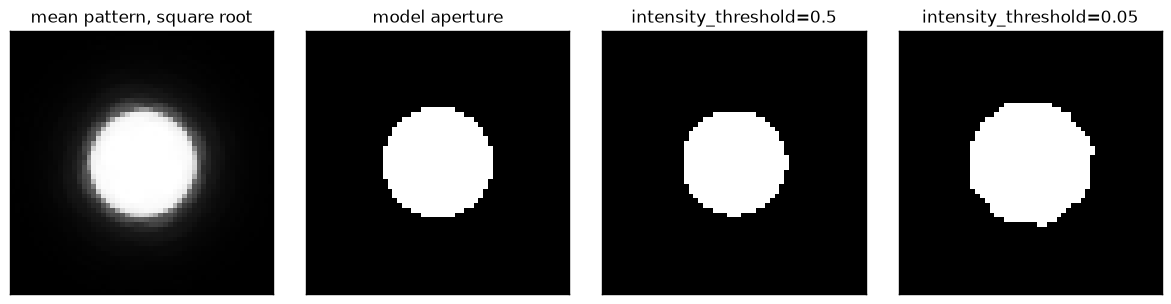

In [10]:
masks = {}
for threshold in (None, 0.5, 0.05):
    masked = em.diffractive_imaging.DirectPtychography.from_dataset4d(
        thick, intensity_threshold=threshold, crop_bf_mask=False, **kwargs
    )
    label = "model aperture" if threshold is None else f"intensity_threshold={threshold}"
    masks[label] = np.fft.fftshift(masked.bf_mask.cpu().numpy())
    print(f"{label:>26}: {masked.num_bf} bright-field pixels")

em.visualization.show_2d(
    [np.sqrt(thick.mean((0, 1)))] + list(masks.values()),
    title=["mean pattern, square root"] + list(masks),
    axsize=(3, 3),
);

WDD in particular models the intensity in every pixel the aperture reaches, and warns when the
mask leaves part of the probe outside it.

## Upsampling

The scan above samples the bright field's band limit, $2\alpha / \lambda$ = 2.5 A$^{-1}$, at its
Nyquist frequency. Every second scan position leaves a 0.4 A step, and `upsampling_factor=2`
recovers the full-resolution reconstruction from it, since each bright-field pixel sees the
aliased frequencies with a different phase.

  kernel   vs full scan   vs truth
     ssb          0.995      0.886
     obf          0.994      0.886
  wiener          0.996      0.923
     wdd          0.960      0.908
    prlx          0.994      0.861
    icom          0.708     -0.121


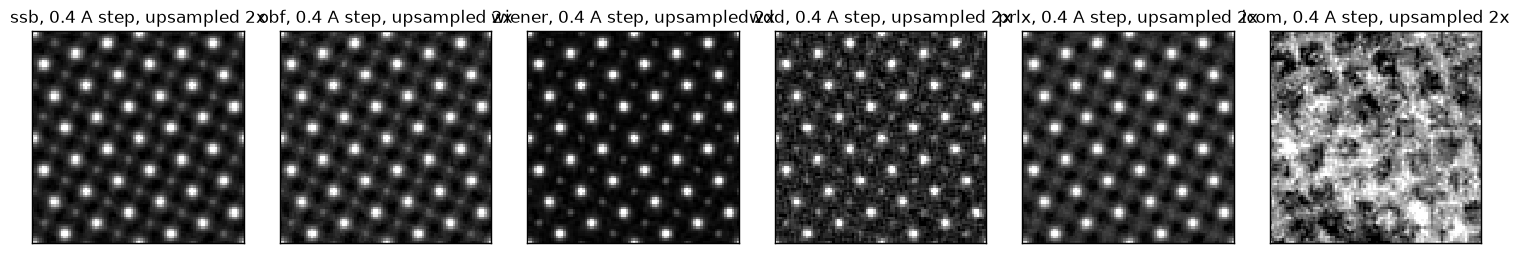

In [11]:
noisy_film = add_poisson_noise(film, 1e5)
full = em.diffractive_imaging.DirectPtychography.from_dataset4d(noisy_film, **kwargs)
half = em.diffractive_imaging.DirectPtychography.from_dataset4d(noisy_film[::2, ::2], **kwargs)

upsampled = []
print(f"{'kernel':>8} {'vs full scan':>14} {'vs truth':>10}")
for kernel in kernels:
    reference = full.reconstruct(deconvolution_kernel=kernel).corrected_bf.cpu().numpy()
    image = half.reconstruct(deconvolution_kernel=kernel, upsampling_factor=2).corrected_bf.cpu().numpy()
    upsampled.append(image)
    print(f"{kernel:>8} {correlation(image, reference):14.3f} {correlation(image, film_truth):10.3f}")

em.visualization.show_2d(
    upsampled,
    title=[f"{kernel}, 0.4 A step, upsampled 2x" for kernel in kernels],
    axsize=(2.5, 2.5),
);

SSB, OBF, Wiener and parallax recover the full-scan reconstruction from a quarter of the
positions. WDD loses a little more, and iCoM the most.

## Summary

| step | call |
|---|---|
| build | `DirectPtychography.from_dataset4d(dataset, energy=..., semiangle_cutoff=..., rotation_angle=..., aberration_coefs=...)` |
| reconstruct | `reconstruct(deconvolution_kernel="obf")`, then `obj` |
| every kernel | `_reconstruct_all_permutations()` |
| bright-field mask | `intensity_threshold=...`, the model aperture by default |
| undersampled scans | `reconstruct(upsampling_factor=2)` |

The next four notebooks apply these kernels to other specimens: a crystal under different
aberrations, a phase object on graphene, apoferritin at cryo-EM conditions, and experimental gold
nanoparticles. `ptycho_direct_06_hyperparameters` covers estimating the aberrations and rotation
when they are not known.